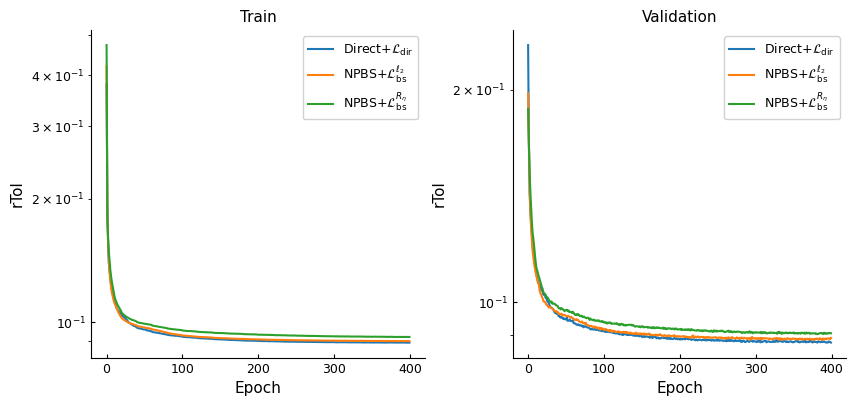

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
mpl.rcParams.update({
    'font.size':         10,
    'axes.labelsize':    11,
    'axes.titlesize':    11,
    'legend.fontsize':   9,
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
    'axes.linewidth':    0.8,
    'lines.linewidth':   1.5,
    'legend.framealpha': 0.9,
    'legend.edgecolor':  '0.8',
})

base = '../outputs/2d/openfwi/CurveFault_B/ppw12'
experiments = {
    'pafno_bs_nopre':     r'Direct+$\mathcal{L}_{\text{dir}}$',
    'pafno_bs_nopreloss': r'NPBS+$\mathcal{L}_{\text{bs}}^{\ell_2}$',
    'pafno_bs_pre':       r'NPBS+$\mathcal{L}_{\text{bs}}^{R_\eta}$',
}

fig, axes = plt.subplots(1, 2, figsize=(8.5, 4.0))

for name, label in experiments.items():
    exp_dir = os.path.join(base, name)
    train_loss = np.loadtxt(os.path.join(exp_dir, 'train_loss_epoch.txt'))
    val_loss   = np.loadtxt(os.path.join(exp_dir, 'val_loss_step.txt'))

    axes[0].plot(np.arange(len(train_loss)), train_loss, label=label)
    axes[1].plot(np.arange(len(val_loss)),   val_loss,   label=label)

for ax, title in zip(axes, ['Train', 'Validation']):
    ax.set_yscale('log')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('rTol')
    ax.set_title(title)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(direction='in', length=3)
    ax.legend()

plt.tight_layout(pad=0.5)
plt.savefig('train_val_loss.png', dpi=300, bbox_inches='tight')
plt.show()